In [41]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, classification_report, r2_score, mean_squared_error

In [42]:
df = pd.read_json('movies_sample.json')

df.head()

,id,title,title_fa,year,genres,moods,rating,poster
0,1,Inside Out,درون و بیرون,2015,"[animation, comedy, drama]","[happy, sad]",8.1,
1,2,The Intouchables,دست‌نیافتنی‌ها,2011,"[comedy, drama]","[sad, neutral]",8.5,
2,3,Up,بالا,2009,"[animation, adventure]","[sad, happy]",8.3,
3,4,The Grand Budapest Hotel,هتل بزرگ بوداپست,2014,[comedy],"[happy, neutral]",8.1,
4,5,Interstellar,میان‌ستاره‌ای,2014,"[sci-fi, drama]","[surprise, neutral]",8.7,


In [43]:
print(df.isnull().sum())
print(df['rating'].describe())

id          0
title       0
title_fa    0
year        0
genres      0
moods       0
rating      0
poster      0
dtype: int64
count    24.000
mean      8.275
std       0.397
min       7.400
25%       8.000
50%       8.200
75%       8.500
max       9.300
Name: rating, dtype: float64


In [44]:
genre_list = sorted({g for genres in df['genres'] for g in genres})
mood_list = sorted({m for moods in df['moods'] for m in moods})

for g in genre_list:
    df[g] = df['genres'].apply(lambda x: int(g in x))
for m in mood_list:
    df['mood_' + m] = df['moods'].apply(lambda x: int(m in x))

threshold = df['rating'].median()
df['is_good'] = (df['rating'] >= threshold).astype(int)

print('threshold:', threshold)
print(df['is_good'].value_counts())

threshold: 8.2
is_good
1    13
0    11
Name: count, dtype: int64


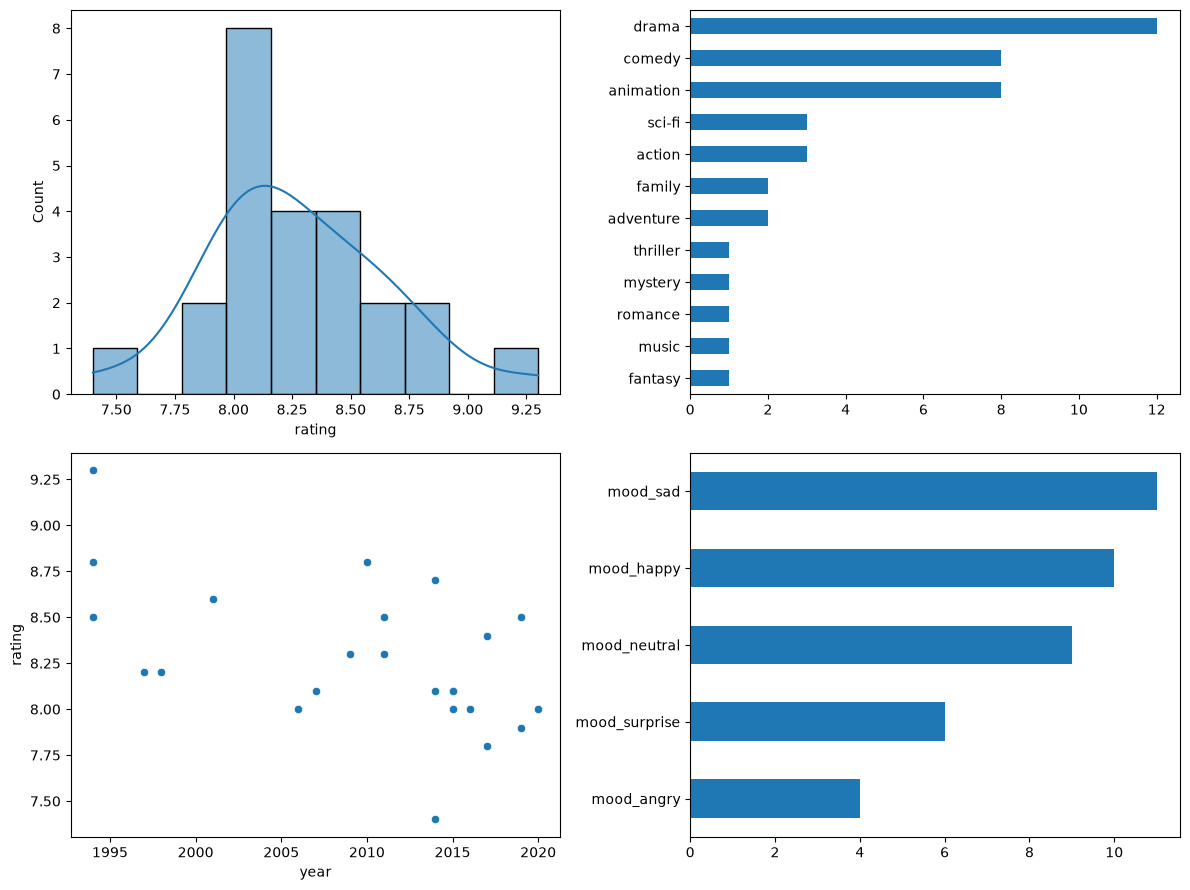

In [45]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

sns.histplot(df['rating'], bins=10, kde=True, ax=axes[0, 0])
df[genre_list].sum().sort_values().plot(kind='barh', ax=axes[0, 1])
sns.scatterplot(x='year', y='rating', data=df, ax=axes[1, 0])
df[['mood_' + m for m in mood_list]].sum().sort_values().plot(kind='barh', ax=axes[1, 1])

plt.tight_layout()
plt.show()

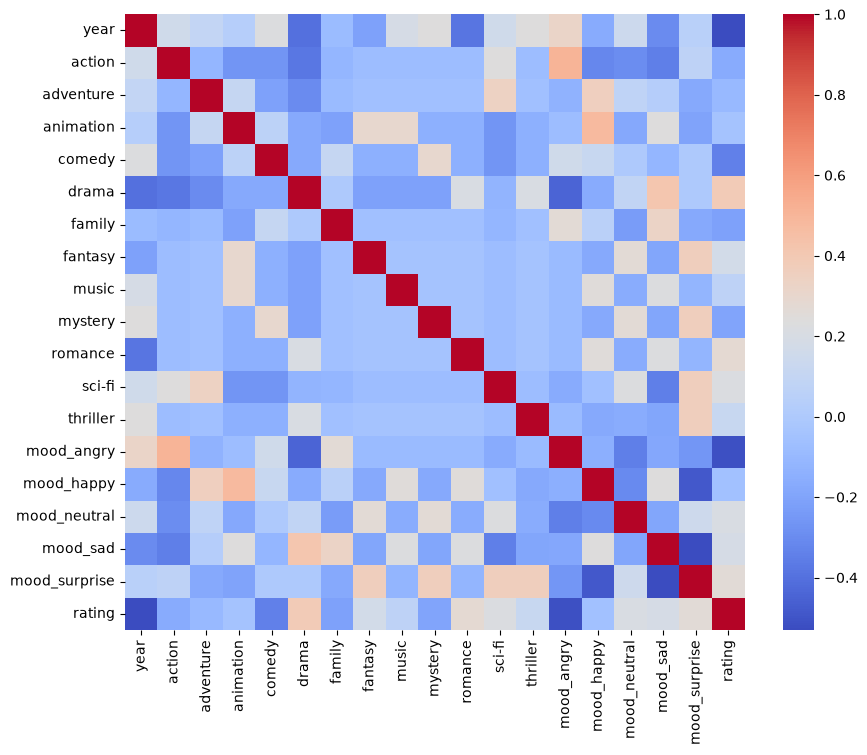

In [46]:
mood_cols = ['mood_' + m for m in mood_list]
features = ['year'] + genre_list + mood_cols

plt.figure(figsize=(10, 8))
sns.heatmap(df[features + ['rating']].corr(), cmap='coolwarm')
plt.show()

In [47]:
x = df[features]
y = df['is_good']
rating = df['rating']

x_train, x_test, y_train, y_test, rating_train, rating_test = train_test_split(x, y, rating, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [48]:
models = {'Logistic Regression': LogisticRegression(max_iter=1000),'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),'KNN': KNeighborsClassifier(n_neighbors=3),}

best_score = 0

for name, model in models.items():
    score = cross_val_score(model, x_train, y_train, cv=3).mean()
    print(name, ':', round(score, 3))
    if score > best_score:
        best_score = score
        best_name = name

best_model = models[best_name]
best_model.fit(x_train, y_train)
best_pred = best_model.predict(x_test)
print('Best model:', best_name)

Logistic Regression : 0.611
Random Forest : 0.611
KNN : 0.611
Best model: Logistic Regression


              precision    recall  f1-score   support

           0       0.67      0.67      0.67         3
           1       0.67      0.67      0.67         3

    accuracy                           0.67         6
   macro avg       0.67      0.67      0.67         6
weighted avg       0.67      0.67      0.67         6



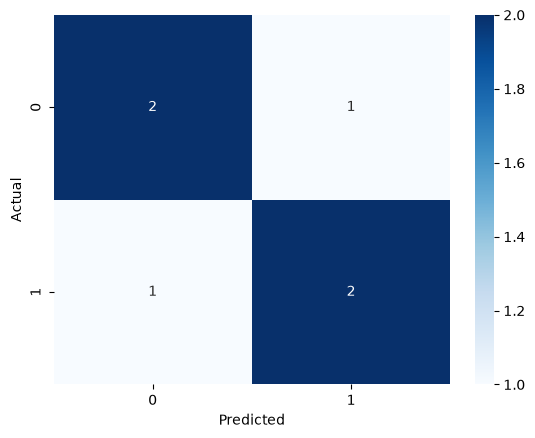

In [49]:
print(classification_report(y_test, best_pred, zero_division=0))

sns.heatmap(confusion_matrix(y_test, best_pred), annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

In [50]:
reg = RandomForestRegressor(n_estimators=200, random_state=42)
reg.fit(x_train, rating_train)
reg_pred = reg.predict(x_test)

print('R2   :', round(r2_score(rating_test, reg_pred), 3))
print('RMSE :', round(mean_squared_error(rating_test, reg_pred) ** 0.5, 3))

R2   : -0.257
RMSE : 0.357


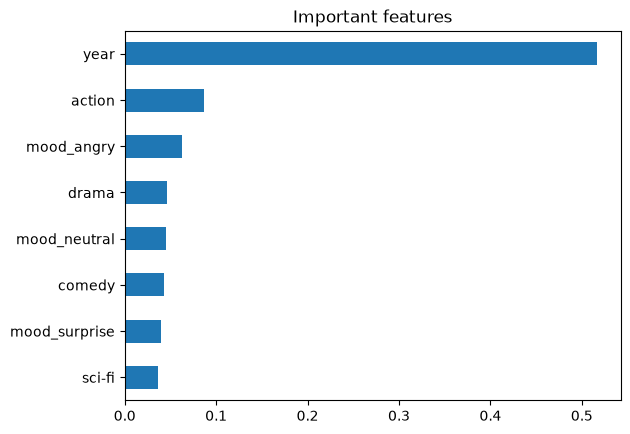

In [51]:
importance = pd.Series(reg.feature_importances_, index=features).sort_values()

importance.tail(8).plot(kind='barh')
plt.title('Important features')
plt.show()

In [52]:
print('Genres:', ', '.join(genre_list))
print('Moods:', ', '.join(mood_list))

while True:
    try:
        year = int(input('سال ساخت: '))
    except ValueError:
        print('لطفا سال را عدد وارد کن.')
        continue

    chosen_genres = [item.strip().lower() for item in input('ژانرها (با کاما جدا کن): ').split(',')]
    chosen_moods = [item.strip().lower() for item in input('حال‌ها (با کاما جدا کن): ').split(',')]
    if not all(g in genre_list for g in chosen_genres) or not all(m in mood_list for m in chosen_moods):
        print('ژانر یا حال معتبر نیست، از لیست بالا انتخاب کن.')
        continue

    row = dict.fromkeys(features, 0)
    row['year'] = year
    for g in chosen_genres:
        row[g] = 1
    for m in chosen_moods:
        row['mood_' + m] = 1

    movie = scaler.transform(pd.DataFrame([row])[features])
    probability = best_model.predict_proba(movie)[0][1]
    predicted_rating = reg.predict(movie)[0]

    print(f'امتیاز پیش‌بینی‌شده: {predicted_rating:.1f}')
    print(f'احتمال بالاتر بودن از میانه‌ی امتیازها: {probability:.0%}')

    if input('فیلم دیگه؟ (y/n): ').strip().lower() != 'y':
        break

Genres: action, adventure, animation, comedy, drama, family, fantasy, music, mystery, romance, sci-fi, thriller
Moods: angry, happy, neutral, sad, surprise
امتیاز پیش‌بینی‌شده: 8.2
احتمال بالاتر بودن از میانه‌ی امتیازها: 88%
